# Sparse-to-Dense on KITTI: train + basic evaluation

Camera + LiDAR depth completion (Ma et al., ICRA 2019) on the KITTI depth selection subset (~2 GB).

**Before you start:** Runtime → Change runtime type → **T4 GPU**, then set `REPO_URL` in the next cell.

| Step | Time on T4 |
|---|---|
| Setup + download | ~5 min |
| Smoke test (`QUICK_TEST = True`) | ~3 min |
| Full training run | `TIME_BUDGET_MIN` (default 30 min) |
| Basic evaluation | ~1 min |

Code is cloned to the Colab disk; checkpoints and results go to Google Drive so they survive a disconnect.

## 0. Settings

In [8]:
REPO_URL = 'https://github.com/chauhansrc/kitti-depth-completion.git'  # <-- change this

PROJECT_DIR = '/content/kitti-code'               # cloned code (Colab disk)
DATA_DIR = '/content/data'                        # dataset (Colab disk: much faster than Drive)
RUNS_DIR = '/content/drive/MyDrive/kitti-runs'    # checkpoints + results (persist on Drive)

QUICK_TEST = False        # True: 1 short epoch to check everything works. Then set False for the real run.
MODALITY = 'rgbd'        # 'rgbd' (camera + LiDAR), 'd' (LiDAR only), 'rgb' (camera only)
LAYERS = 34              # ResNet encoder: 34, or 18 for faster training
EPOCHS = 30
TIME_BUDGET_MIN = 30     # training stops before exceeding this
BATCH_SIZE = 8           # lower to 2 if you get CUDA out-of-memory

RUN_NAME = f'{MODALITY}_r{LAYERS}' + ('_quick' if QUICK_TEST else '')
OUT_DIR = f'{RUNS_DIR}/{RUN_NAME}'
print('Run dir:', OUT_DIR)

Run dir: /content/drive/MyDrive/kitti-runs/rgbd_r34


## 1. Setup: GPU, Drive, code

In [2]:
import os, torch
assert torch.cuda.is_available(), 'No GPU: Runtime -> Change runtime type -> T4 GPU'
print(torch.__version__, '|', torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')

os.makedirs(RUNS_DIR, exist_ok=True)

if os.path.isdir(PROJECT_DIR):
    !git -C {PROJECT_DIR} pull --ff-only
else:
    !git clone {REPO_URL} {PROJECT_DIR}

%cd {PROJECT_DIR}
!git log --oneline -1
!pip install -q -r requirements.txt

2.11.0+cu130 | NVIDIA L4
Mounted at /content/drive
Cloning into '/content/kitti-code'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 2), reused 20 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 15.76 KiB | 15.76 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/kitti-code
e795e7e (HEAD -> main, origin/main, origin/HEAD) README: describe quick-test and auto-resume Colab workflow


## 2. Download data (~2 GB)
Requires a KITTI account with the license accepted. Skips the download if the data is already there.

In [3]:
!bash scripts/download_data.sh {DATA_DIR}

--2026-10-11 16:14:52--  https://s3.eu-central-1.amazonaws.com/avg-kitti/data_depth_selection.zip
Resolving s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)... 3.5.134.100, 3.5.135.205, 3.5.135.124, ...
Connecting to s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)|3.5.134.100|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2010655006 (1.9G) [application/zip]
Saving to: ‘/content/data/data_depth_selection.zip’

/content/data/data_ 100%[===================>]   1.87G  21.9MB/s    in 92s     

2026-10-11 16:16:25 (20.8 MB/s) - ‘/content/data/data_depth_selection.zip’ saved [2010655006/2010655006]

Extracting to /content/data
Done. Frames in val_selection_cropped:
1000


## 3. Check the data
Confirms the files pair up, shows the train/val split, and plots one sample.

In [4]:
import matplotlib.pyplot as plt
from s2d.data import find_samples, split_samples, read_rgb, read_depth
from s2d.vis import colorize, dilate

samples = find_samples(DATA_DIR)
train_s, val_s = split_samples(samples, val_fraction=0.2, seed=0)
print(f'{len(samples)} frames from {len({s["drive"] for s in samples})} drives')
print(f'train: {len(train_s)} frames | val: {len(val_s)} frames')
print('val drives:', sorted({s['drive'] for s in val_s}))

s = samples[0]
rgb, sparse, gt = read_rgb(s['image']), read_depth(s['sparse']), read_depth(s['gt'])
print(f'\n{s["name"]}: image {rgb.shape}')
print(f'LiDAR pixels: {(sparse > 0).mean():.1%} | GT pixels: {(gt > 0).mean():.1%} | GT depth range: {gt[gt > 0].min():.1f}-{gt.max():.1f} m')

fig, axes = plt.subplots(3, 1, figsize=(14, 7))
for ax, (title, img) in zip(axes, [('RGB', rgb),
                                   ('Sparse LiDAR (input, dilated)', colorize(dilate(sparse), 80)),
                                   ('Ground truth (semi-dense)', colorize(gt, 80))]):
    ax.imshow(img); ax.set_title(title, loc='left'); ax.axis('off')
plt.tight_layout(); plt.show()

1000 frames from 13 drives
train: 709 frames | val: 291 frames
val drives: ['2011_09_26_drive_0005_sync', '2011_09_26_drive_0036_sync', '2011_09_28_drive_0037_sync', '2011_09_29_drive_0026_sync']

2011_09_26_drive_0002_sync_image_0000000005_image_02.png: image (352, 1216, 3)
LiDAR pixels: 4.4% | GT pixels: 23.2% | GT depth range: 5.4-80.7 m


## 4. Train
Resumes automatically from `last.pt` if this run was interrupted (e.g. Colab disconnected).

In [9]:
epochs, budget = (1, 3) if QUICK_TEST else (EPOCHS, TIME_BUDGET_MIN)

last_ckpt = f'{OUT_DIR}/last.pt'
resume = f'--resume {last_ckpt}' if os.path.exists(last_ckpt) else ''
if resume:
    print('Resuming from', last_ckpt)

!python train.py --data_root {DATA_DIR} --out_dir {OUT_DIR} --modality {MODALITY} --layers {LAYERS} --epochs {epochs} --time_budget_min {budget} --batch_size {BATCH_SIZE} {resume}

Device: cuda | AMP: True | modality: rgbd
Samples: 709 train / 291 val (9 / 4 drives)
Parameters: 26.1 M
[  1/30] loss 434.275 | RMSE 7142.5 mm | MAE 4955.5 mm | iRMSE 212.47 1/km | iMAE 80.41 1/km | d1 0.4228 | lr 1.0e-04 | 120s *best*
[  2/30] loss 42.616 | RMSE 5348.6 mm | MAE 3634.6 mm | iRMSE 130.13 1/km | iMAE 44.22 1/km | d1 0.5511 | lr 1.0e-04 | 99s *best*
[  3/30] loss 26.167 | RMSE 4682.3 mm | MAE 3038.1 mm | iRMSE 89.63 1/km | iMAE 30.55 1/km | d1 0.6392 | lr 9.9e-05 | 100s *best*
[  4/30] loss 18.972 | RMSE 4385.5 mm | MAE 2846.4 mm | iRMSE 84.99 1/km | iMAE 28.62 1/km | d1 0.6806 | lr 9.8e-05 | 100s *best*
[  5/30] loss 14.809 | RMSE 3603.5 mm | MAE 2285.9 mm | iRMSE 61.36 1/km | iMAE 21.09 1/km | d1 0.7465 | lr 9.6e-05 | 100s *best*
[  6/30] loss 12.726 | RMSE 3276.3 mm | MAE 2057.4 mm | iRMSE 64.53 1/km | iMAE 21.02 1/km | d1 0.7729 | lr 9.3e-05 | 100s *best*
[  7/30] loss 11.131 | RMSE 3087.5 mm | MAE 1964.3 mm | iRMSE 65.79 1/km | iMAE 21.73 1/km | d1 0.7879 | lr 9.1e-

In [10]:
# epochs, budget = (1, 3) if QUICK_TEST else (EPOCHS, TIME_BUDGET_MIN)

last_ckpt = f'{OUT_DIR}/last.pt'
resume = f'--resume {last_ckpt}' if os.path.exists(last_ckpt) else ''
if resume:
    print('Resuming from', last_ckpt)

!python train.py --data_root {DATA_DIR} --out_dir {OUT_DIR} --modality {MODALITY} --layers {LAYERS} --epochs {epochs} --time_budget_min {budget} --batch_size {BATCH_SIZE} {resume}

Resuming from /content/drive/MyDrive/kitti-runs/rgbd_r34/last.pt
Device: cuda | AMP: True | modality: rgbd
Samples: 709 train / 291 val (9 / 4 drives)
Parameters: 26.1 M
Resumed from epoch 16 (best RMSE 2152.0 mm)
[ 18/30] loss 5.474 | RMSE 2180.0 mm | MAE 1258.3 mm | iRMSE 23.80 1/km | iMAE 9.94 1/km | d1 0.9173 | lr 4.0e-05 | 119s
[ 19/30] loss 4.780 | RMSE 2144.8 mm | MAE 1247.5 mm | iRMSE 23.18 1/km | iMAE 9.65 1/km | d1 0.9202 | lr 3.5e-05 | 99s *best*
[ 20/30] loss 4.500 | RMSE 2078.6 mm | MAE 1185.5 mm | iRMSE 24.36 1/km | iMAE 9.67 1/km | d1 0.9254 | lr 3.0e-05 | 99s *best*
[ 21/30] loss 4.427 | RMSE 2077.9 mm | MAE 1188.9 mm | iRMSE 24.44 1/km | iMAE 9.58 1/km | d1 0.9260 | lr 2.6e-05 | 100s *best*
[ 22/30] loss 4.173 | RMSE 2040.9 mm | MAE 1161.8 mm | iRMSE 22.86 1/km | iMAE 9.28 1/km | d1 0.9280 | lr 2.1e-05 | 100s *best*
[ 23/30] loss 4.160 | RMSE 2006.0 mm | MAE 1129.9 mm | iRMSE 23.42 1/km | iMAE 9.17 1/km | d1 0.9329 | lr 1.7e-05 | 100s *best*
[ 24/30] loss 4.040 | RMSE 

## 5. Training curves

In [11]:
import pandas as pd

h = pd.read_csv(f'{OUT_DIR}/history.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(h['epoch'], h['train_loss'], marker='o'); axes[0].set_title('train loss (masked L2, m²)')
axes[1].plot(h['epoch'], h['rmse'], marker='o', color='C1'); axes[1].set_title('val RMSE (mm)')
axes[2].plot(h['epoch'], h['mae'], marker='o', color='C2'); axes[2].set_title('val MAE (mm)')
for ax in axes:
    ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best = h.loc[h['rmse'].idxmin()]
print(f"Best epoch {int(best['epoch'])}: RMSE {best['rmse']:.0f} mm, MAE {best['mae']:.0f} mm "
      f"| total train time {h['epoch_time_s'].sum() / 60:.1f} min")

Best epoch 29: RMSE 1961 mm, MAE 1095 mm | total train time 50.6 min


## 6. Basic evaluation
Metrics on the held-out validation drives with the best checkpoint, plus example predictions.

For reference, the paper's supervised model reaches ~815 mm RMSE on the official test set after training on
~86k frames. With ~800 training frames, expect noticeably higher error here.

In [12]:
!python evaluate.py --checkpoint {OUT_DIR}/best.pt --data_root {DATA_DIR} --num_vis 6

Loaded /content/drive/MyDrive/kitti-runs/rgbd_r34/best.pt (epoch 29, modality rgbd)
Evaluating 291 frames
RMSE 1961.4 mm | MAE 1095.1 mm | iRMSE 21.50 1/km | iMAE 8.72 1/km | d1 0.9378
Saved metrics and 6 visualizations to /content/drive/MyDrive/kitti-runs/rgbd_r34/eval


In [13]:
import json

m = json.load(open(f'{OUT_DIR}/eval/metrics.json'))
pd.DataFrame([{
    'modality': m['modality'], 'epoch': m['epoch'], 'val frames': m['num_frames'],
    'RMSE (mm)': m['rmse'], 'MAE (mm)': m['mae'],
    'iRMSE (1/km)': m['irmse'], 'iMAE (1/km)': m['imae'], 'δ<1.25': m['delta1'],
}]).round(3)

,modality,epoch,val frames,RMSE (mm),MAE (mm),iRMSE (1/km),iMAE (1/km),δ<1.25
0,rgbd,29,291,1961.405,1095.145,21.497,8.725,0.938


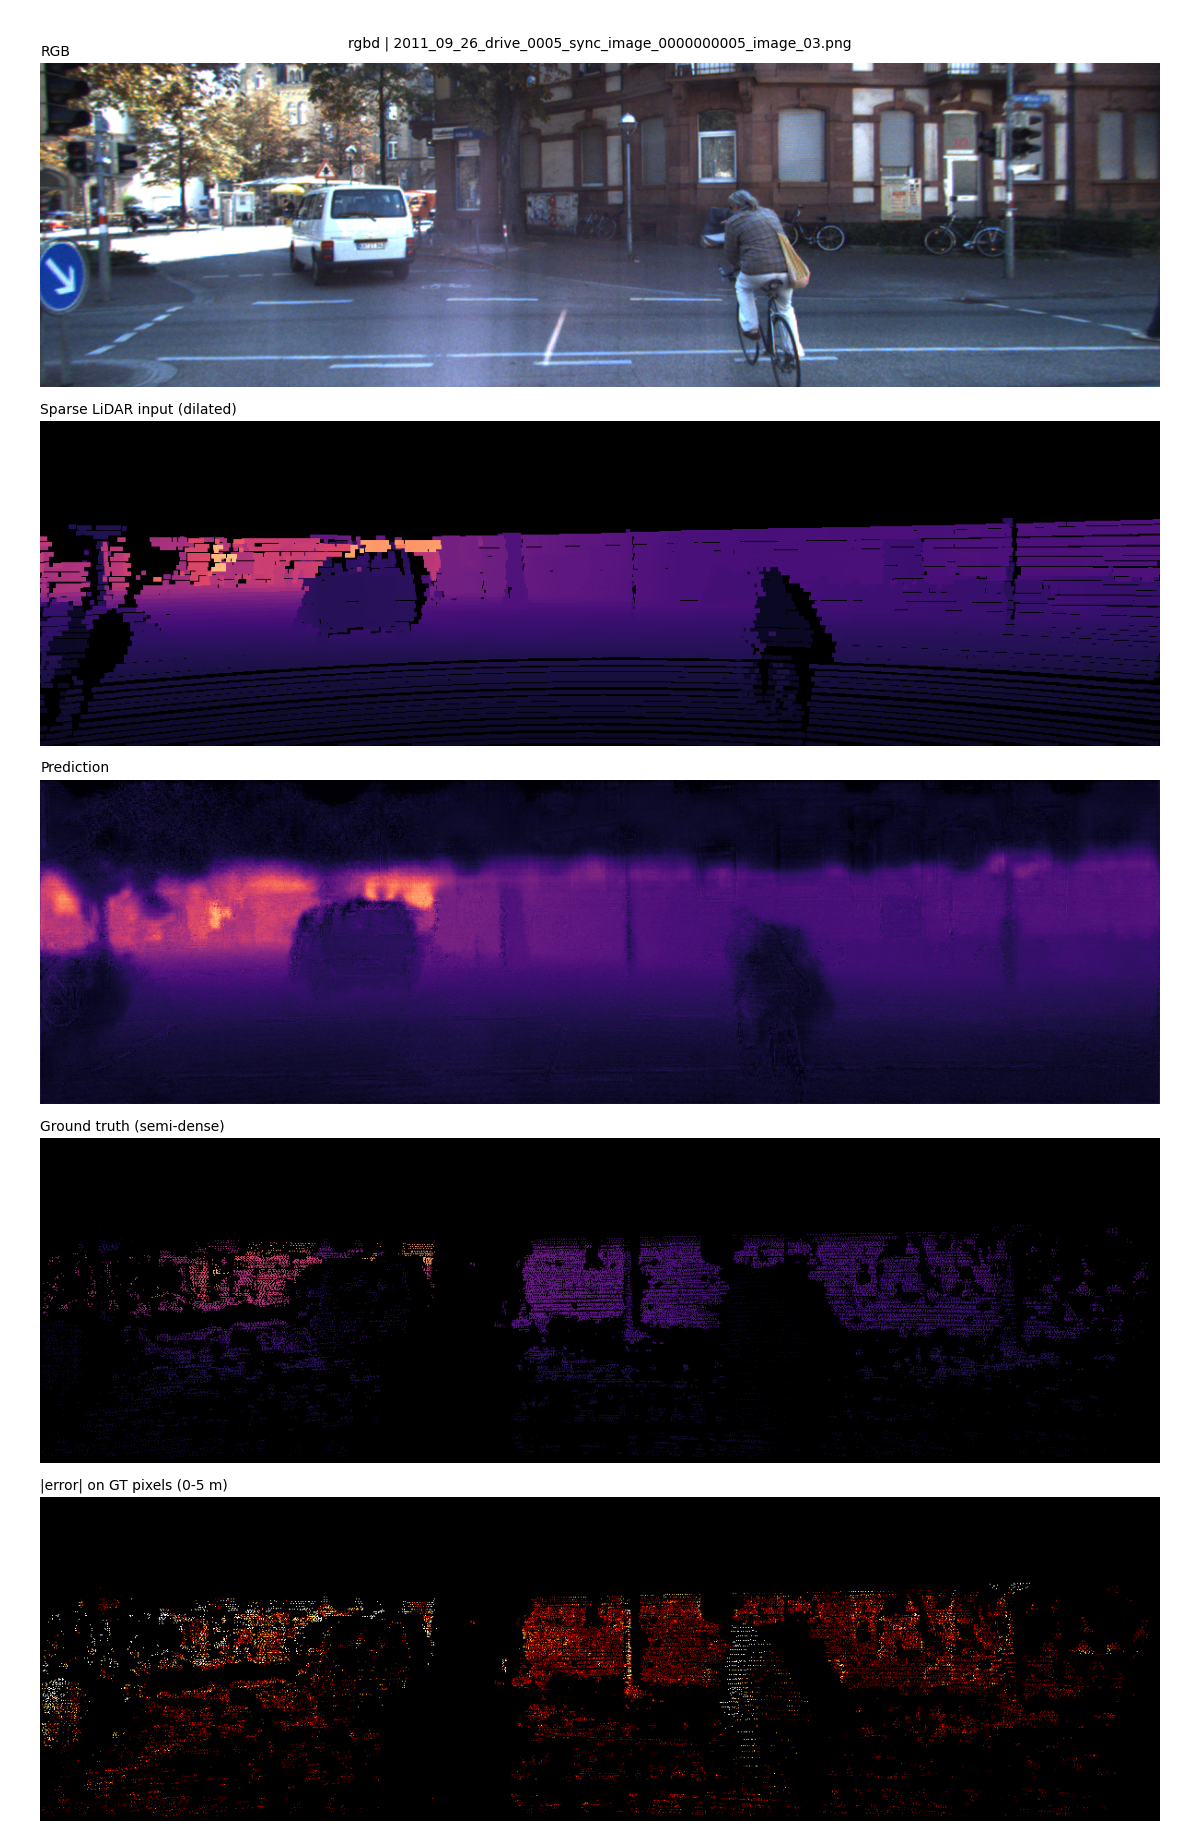

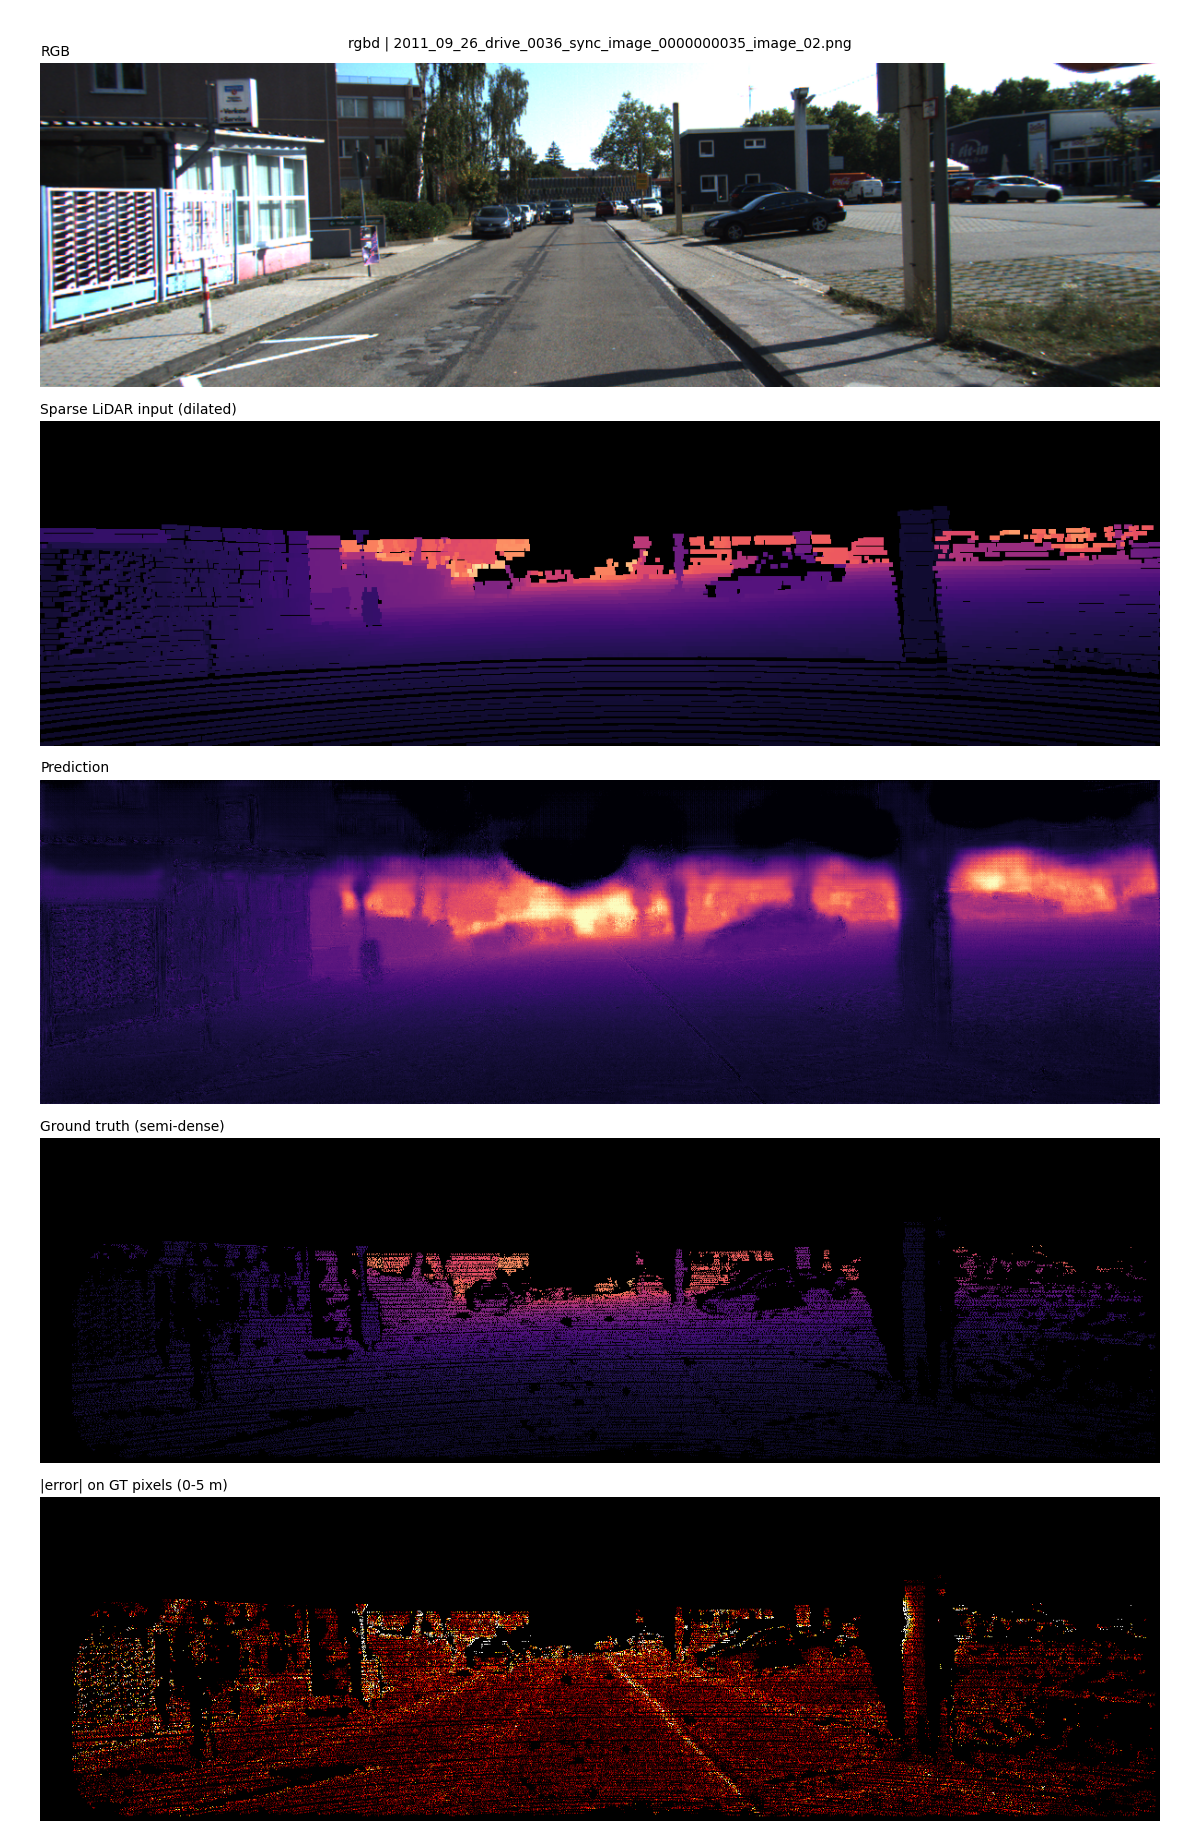

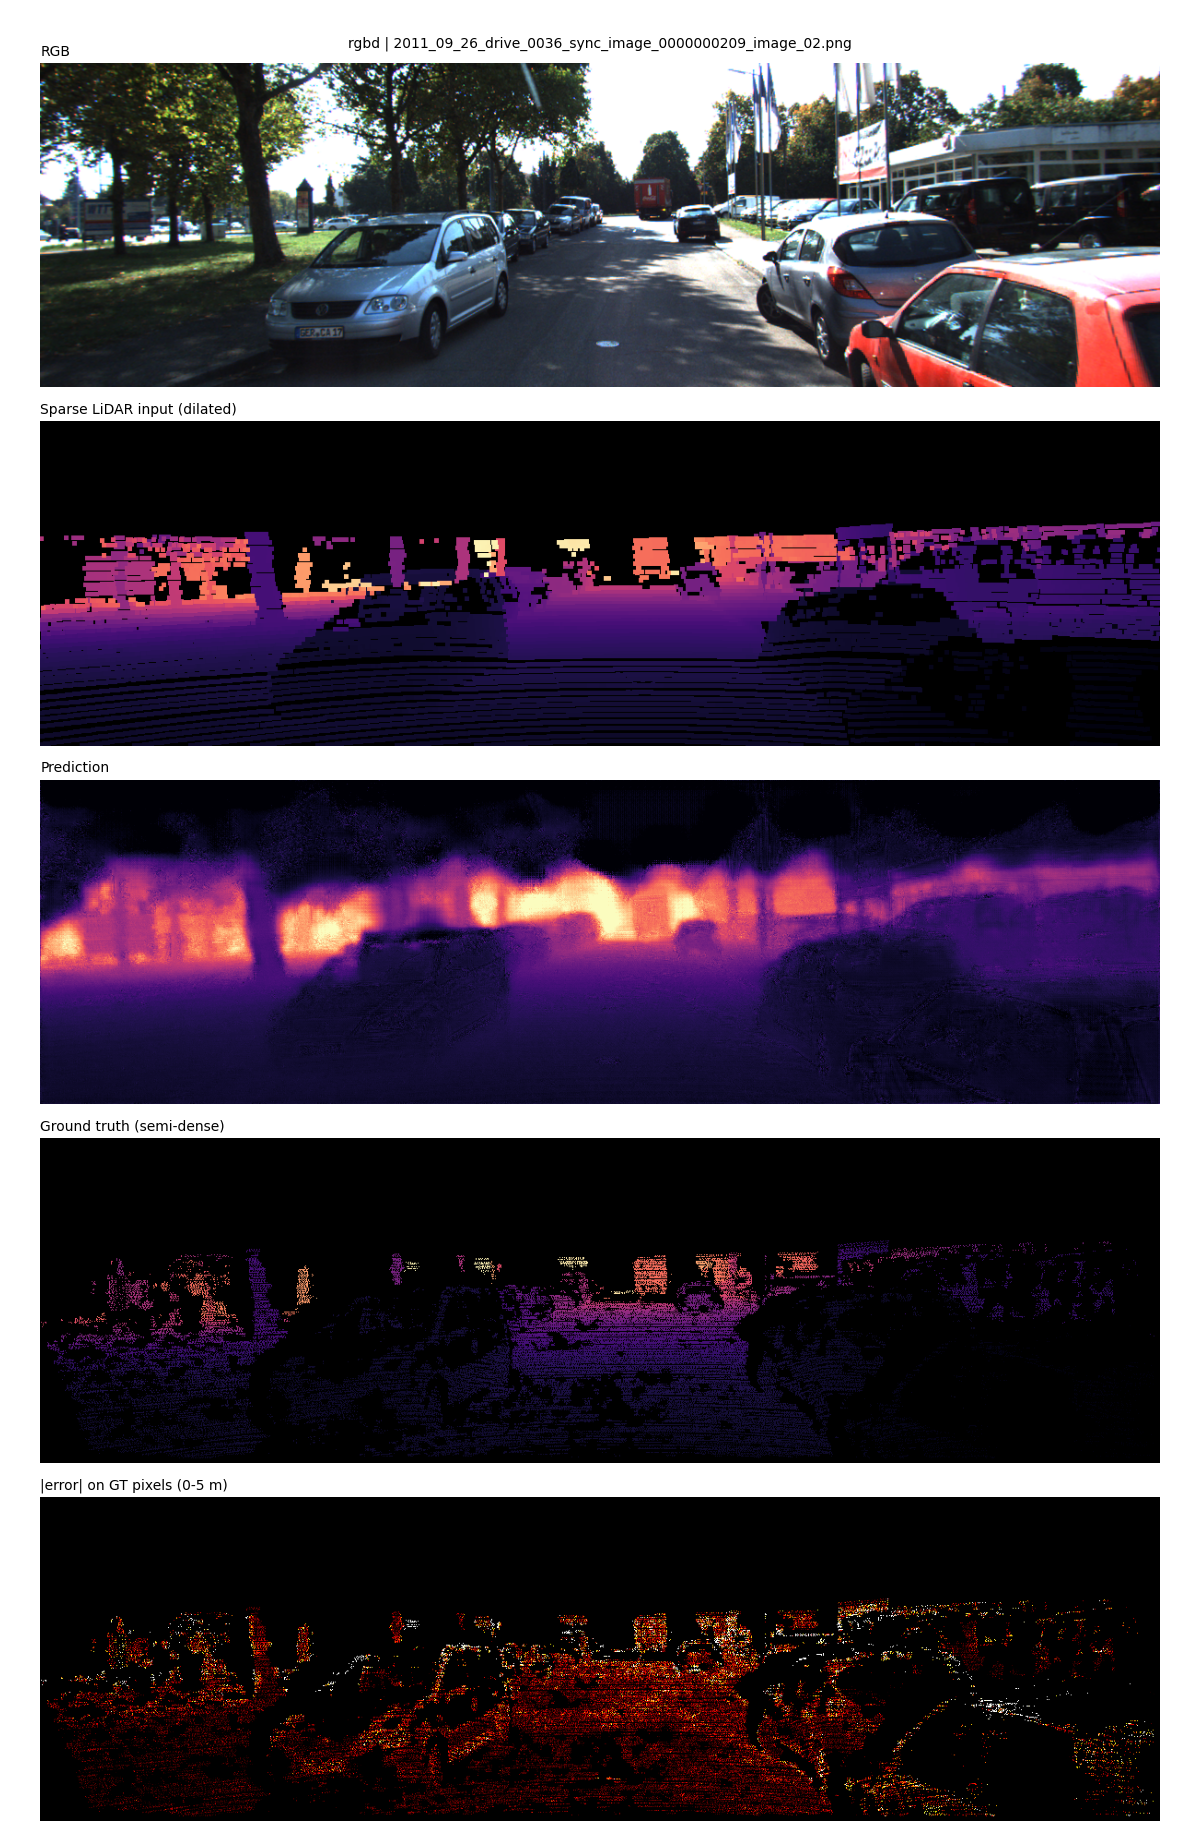

In [14]:
import glob
from IPython.display import Image, display

# Each panel: RGB | sparse LiDAR input | prediction | ground truth | absolute error
for p in sorted(glob.glob(f'{OUT_DIR}/eval/vis/*.png'))[:3]:
    display(Image(filename=p))